# Notebook 03 — Train-Only User/Item EDA & Retrieval Readiness

**Goal:** Profile retrieval training histories and validation/test cohort coverage without using future labels to construct features. Run all cells from top to bottom. No training yet.

**Protocol:** Validation retrieval candidates/features use only `train_history` (< 2015-08-01 UTC). Test retrieval candidates/features may use `test_history` (< 2015-09-01 UTC), after all design decisions have been frozen. Validation labels are **only** used for evaluation/cohort diagnostics, never to compute popularity or user features. This dataset is interaction-only, **not** impression logs.

## 1. Load temporal artifacts and validate boundaries

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == 'notebooks' else cwd
DATA_DIR = PROJECT_ROOT / 'data' / 'processed'
REPORT_DIR = PROJECT_ROOT / 'reports'
REPORT_DIR.mkdir(parents=True, exist_ok=True)

names = ['train_history', 'validation_future_events', 'test_history', 'test_future_events',
         'validation_view_labels_all', 'validation_view_labels_warm_users',
         'validation_view_labels_warm_users_items', 'test_view_labels_all',
         'test_view_labels_warm_users', 'test_view_labels_warm_users_items']
for name in names:
    assert (DATA_DIR / f'{name}.csv').is_file(), f'Missing {name}.csv; cwd={cwd}'

def load(name):
    return pd.read_csv(DATA_DIR / f'{name}.csv')

train = load('train_history')
val_future = load('validation_future_events')
val_labels_all = load('validation_view_labels_all')
val_labels_warm = load('validation_view_labels_warm_users')
val_labels_warm_items = load('validation_view_labels_warm_users_items')
print('Train rows:', f'{len(train):,}', 'Validation future rows:', f'{len(val_future):,}')
print('Validation label pairs (all/warm users/warm users+items):',
      len(val_labels_all), len(val_labels_warm), len(val_labels_warm_items))

VAL_START_MS = pd.Timestamp('2015-08-01', tz='UTC').value // 10**6
VAL_END_MS = pd.Timestamp('2015-08-15', tz='UTC').value // 10**6
assert train.timestamp.max() < VAL_START_MS
assert val_future.timestamp.between(VAL_START_MS, VAL_END_MS - 1).all()
assert train.timestamp.is_monotonic_increasing
assert val_labels_warm.visitorid.isin(train.visitorid).all()
assert val_labels_warm_items.itemid.isin(train.itemid).all()
assert not val_labels_warm.duplicated(['visitorid','itemid']).any()
print('PASS: validation history and label boundaries')

Train rows: 1,899,029 Validation future rows: 252,086
Validation label pairs (all/warm users/warm users+items): 200935 28634 26155
PASS: validation history and label boundaries


## 2. Training-history activity and catalog statistics

All user/item statistics below are computed from **train** only. We deliberately avoid full-dataset counts.

In [2]:
user_counts = train.groupby('visitorid').size().sort_values(ascending=False)
item_counts = train.groupby('itemid').size().sort_values(ascending=False)
unique_pairs = train[['visitorid','itemid']].drop_duplicates().shape[0]
train_stats = {
    'train_events': int(len(train)),
    'train_users': int(len(user_counts)),
    'train_items': int(len(item_counts)),
    'train_unique_user_item_pairs': int(unique_pairs),
    'train_user_item_density': float(unique_pairs / (len(user_counts) * len(item_counts))),
    'train_users_one_event_pct': float((user_counts == 1).mean() * 100),
    'train_items_one_event_pct': float((item_counts == 1).mean() * 100),
    'train_user_event_median': float(user_counts.median()),
    'train_user_event_p99': float(user_counts.quantile(.99)),
    'train_item_event_median': float(item_counts.median()),
}
display(pd.Series(train_stats, name='value').to_frame())
print('Train event mix (%):')
display((train.event.value_counts(normalize=True) * 100).round(2))

,value
train_events,1.899029e+06
train_users,9.625280e+05
train_items,1.996890e+05
train_unique_user_item_pairs,1.472639e+06
train_user_item_density,7.661764e-06
train_users_one_event_pct,7.119585e+01
train_items_one_event_pct,3.393477e+01
train_user_event_median,1.000000e+00
train_user_event_p99,1.300000e+01
train_item_event_median,3.000000e+00


Train event mix (%):


event
view           96.72
addtocart       2.47
transaction     0.81
Name: proportion, dtype: float64

## 3. Distribution plots (train only)

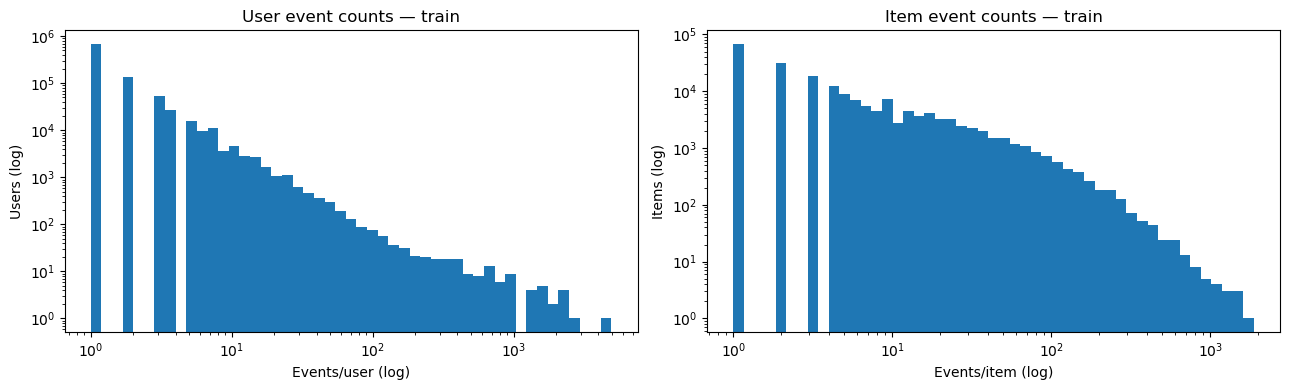

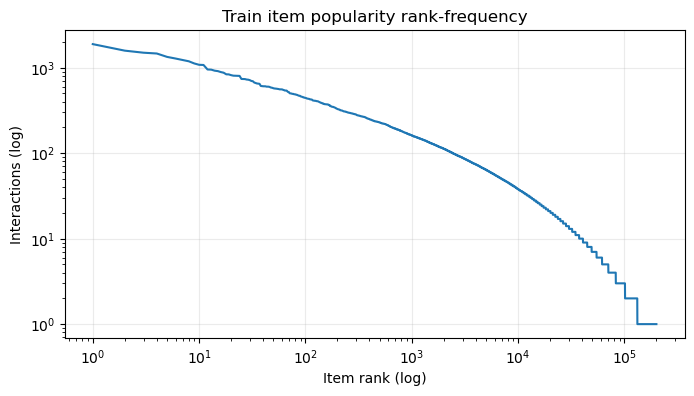

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(user_counts.to_numpy(), bins=np.logspace(0, np.log10(user_counts.max()+1), 50))
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set(title='User event counts — train', xlabel='Events/user (log)', ylabel='Users (log)')
axes[1].hist(item_counts.to_numpy(), bins=np.logspace(0, np.log10(item_counts.max()+1), 50))
axes[1].set_xscale('log'); axes[1].set_yscale('log')
axes[1].set(title='Item event counts — train', xlabel='Events/item (log)', ylabel='Items (log)')
plt.tight_layout(); plt.show()

rank = np.arange(1, len(item_counts)+1)
plt.figure(figsize=(8, 4))
plt.loglog(rank, item_counts.to_numpy())
plt.title('Train item popularity rank-frequency')
plt.xlabel('Item rank (log)'); plt.ylabel('Interactions (log)')
plt.grid(alpha=.25); plt.show()

## 4. Train-only popularity concentration

Popularity measures **logged interactions**, not impression-normalized preference or CTR.

In [4]:
pop_shares = {}
for fraction in [0.01, 0.10]:
    n_top = max(1, int(np.ceil(len(item_counts) * fraction)))
    pop_shares[f'top_{int(fraction*100)}pct_interaction_share'] = float(item_counts.head(n_top).sum() / len(train))
print({k: f'{v:.2%}' for k, v in pop_shares.items()})

{'top_1pct_interaction_share': '21.80%', 'top_10pct_interaction_share': '62.20%'}


## 5. Validation evaluation-cohort diagnostics

These are **diagnostics**, not retrieval results. `labels_all` includes cold users. `labels_warm` includes only users seen in the train history. `labels_warm_items` also requires the item to appear in train. Do not infer recommendation recall from these ratios.

In [5]:
def cohort_summary(labels):
    return {'pairs': int(len(labels)),
            'users': int(labels.visitorid.nunique()),
            'items': int(labels.itemid.nunique())}
cohorts = {
    'all_future_view_pairs': cohort_summary(val_labels_all),
    'warm_user_pairs': cohort_summary(val_labels_warm),
    'warm_user_warm_item_pairs': cohort_summary(val_labels_warm_items),
}
display(pd.DataFrame(cohorts).T)
print('Warm-user positive-pair share:', f'{len(val_labels_warm)/len(val_labels_all):.2%}')
print('Warm-user + warm-item positive-pair share:', f'{len(val_labels_warm_items)/len(val_labels_all):.2%}')
print('Warm-item share among warm-user pairs:', f'{len(val_labels_warm_items)/len(val_labels_warm):.2%}')

# All train-history users are eligible for candidate generation, but many have no future label.
print('Train-history users:', f'{train.visitorid.nunique():,}')
print('Warm validation users with at least one future view:', f'{val_labels_warm.visitorid.nunique():,}')

,pairs,users,items
all_future_view_pairs,200935,145763,73730
warm_user_pairs,28634,13329,19240
warm_user_warm_item_pairs,26155,12689,17111


Warm-user positive-pair share: 14.25%
Warm-user + warm-item positive-pair share: 13.02%
Warm-item share among warm-user pairs: 91.34%
Train-history users: 962,528
Warm validation users with at least one future view: 13,329


## 6. Warm validation user history length

This feature is computed from train history only. It can be used for future evaluation segmentation. No validation interactions are included in the count.

In [6]:
val_user_history = (val_labels_warm[['visitorid']].drop_duplicates()
                    .assign(history_events=lambda d: d.visitorid.map(user_counts)))
assert val_user_history.history_events.notna().all()

def activity_bucket(x):
    if x == 1: return '1'
    if x <= 5: return '2-5'
    if x <= 20: return '6-20'
    return '>20'
val_user_history['history_bucket'] = val_user_history.history_events.map(activity_bucket)
order = ['1','2-5','6-20','>20']
user_bucket_counts = val_user_history.history_bucket.value_counts().reindex(order, fill_value=0)
display(pd.DataFrame({'users': user_bucket_counts,
                      'pct': (user_bucket_counts / len(val_user_history) * 100).round(2)}))

# Count *positive pairs*, separately from distinct users, per historical-activity bucket.
val_pairs_with_bucket = val_labels_warm.merge(val_user_history[['visitorid','history_bucket']],
                                              on='visitorid', how='left', validate='many_to_one')
pair_bucket_counts = val_pairs_with_bucket.history_bucket.value_counts().reindex(order, fill_value=0)
display(pd.DataFrame({'positive_pairs': pair_bucket_counts,
                      'pct': (pair_bucket_counts / len(val_pairs_with_bucket) * 100).round(2)}))

,users,pct
history_bucket,,
1,5969,44.78
2-5,4851,36.39
6-20,1884,14.13
>20,625,4.69


,positive_pairs,pct
history_bucket,,
1,8608,30.06
2-5,7901,27.59
6-20,4374,15.28
>20,7751,27.07


## 7. Simple train-only popularity candidate pool diagnostic

This is **not** an evaluated retrieval model: it only checks whether a train-derived popular-item list intersects validation positives. A formal Recall@K evaluation will be implemented in Notebook 04 with consistent user-level denominators and eligibility rules.

In [7]:
popular_100 = set(item_counts.head(100).index)
val_pair_hit_count = int(val_labels_warm_items.itemid.isin(popular_100).sum())
print('Top-100 train-popular items appearing in warm-user+item positive pairs:',
      f'{val_pair_hit_count:,} / {len(val_labels_warm_items):,}')
print('Pair-level overlap (NOT Recall@100):',
      f'{val_pair_hit_count/len(val_labels_warm_items):.2%}')
assert popular_100.issubset(set(train.itemid.unique()))

Top-100 train-popular items appearing in warm-user+item positive pairs: 750 / 26,155
Pair-level overlap (NOT Recall@100): 2.87%


## 8. Save a reproducible report (no future-derived features)

The JSON includes validation cohort diagnostics for reporting; **never merge validation labels into training features**.

In [8]:
report = {
    'protocol': {'validation_history_end_exclusive_utc': '2015-08-01',
                 'validation_label_window_start_utc': '2015-08-01',
                 'validation_label_window_end_exclusive_utc': '2015-08-15',
                 'train_only_features': True},
    'train_stats': train_stats,
    'train_popularity': pop_shares,
    'validation_cohorts': cohorts,
    'validation_warm_users_by_history_bucket': {str(k): int(v) for k,v in user_bucket_counts.items()},
    'validation_positive_pairs_by_history_bucket': {str(k): int(v) for k,v in pair_bucket_counts.items()},
}
out_path = REPORT_DIR / 'notebook03_train_only_eda.json'
with out_path.open('w', encoding='utf-8') as f:
    json.dump(report, f, indent=2)
print('Saved:', out_path)
assert train.timestamp.max() < VAL_START_MS
assert sum(user_bucket_counts) == val_labels_warm.visitorid.nunique()
assert sum(pair_bucket_counts) == len(val_labels_warm)
print('PASS: train-only feature boundaries and cohort consistency')

Saved: C:\YR_Python_Code\multi-stage-ads-recommendation\notebooks\reports\notebook03_train_only_eda.json
PASS: train-only feature boundaries and cohort consistency


## Summary / handoff to Notebook 04

- All user and item activity statistics were computed from **pre-validation train history**.
- Validation labels were used only to describe evaluation cohorts and diagnostic overlap.
- Popularity baseline retrieval must be fitted **separately for each cutoff**.
- Retrieval evaluation should report Recall@K / HitRate@K with clearly defined warm-user and warm-item cohorts, plus candidate coverage and fallback behavior.
- **No future interactions as features; no unobserved pair is automatically a true negative.**